# ECE 285 HW1 — VAE on Chest X-Ray (Pneumonia) images

One VAE trained on all chest X-rays (NORMAL + PNEUMONIA together, per Piazza @46).
Pipeline: load data -> train a convolutional VAE -> plot loss curves -> sample images
-> compute FID and Inception Score with PyTorch-Ignite (following
https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/).

**Kaggle setup:** Add Input -> dataset `paultimothymooney/chest-xray-pneumonia`;
Settings -> Accelerator = GPU T4; Settings -> Internet = On (needed to pip-install
ignite and download the Inception-v3 weights). Then Run All.
Everything is written to `/kaggle/working/outputs/` (or `./outputs/` elsewhere).

In [19]:
# Kaggle images usually ship ignite; this is a no-op if it is already installed.
import subprocess, sys
try:
    import ignite  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytorch-ignite"], check=True)

In [20]:
import argparse
import json
import math
import os
import random
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.utils as vutils
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

# ---- Hyperparameters (edit here, or override from the command line) ----
CFG = dict(
    data_root=None,          # None = auto-detect the folder that contains train/ and test/
    out_dir=None,            # None = /kaggle/working/outputs on Kaggle, ./outputs otherwise
    img_size=64,             # 64 or 128 (must be 4 * 2^k)
    latent_dim=128,
    base_channels=32,        # encoder channels: 32, 64, 128, 256 (, 512 for 128px)
    batch_size=128,
    epochs=100,
    lr=1e-3,
    beta=1.0,                # weight on the KL term (beta = 1 is the standard VAE)
    kl_warmup_epochs=10,     # linearly anneal KL weight 0 -> beta over these epochs (0 = off)
    recon_loss="bce",        # "bce" (Bernoulli decoder) or "mse" (Gaussian decoder, fixed variance)
    seed=42,
    num_workers=2,
    # Evaluation (FID / IS)
    eval_ref="train",        # real reference set for FID: "train" or "test" (test has only 624 images)
    n_eval=2500,             # real/fake images for FID & IS. Keep > 2048 (largest feature dim used):
                             # with fewer, the covariance is singular and ignite's FID raises
                             # "Imaginary component nan".
    eval_batch_size=64,
    real_baseline=True,      # also score a disjoint set of real images: FID floor and IS of real X-rays
)


def get_cfg():
    """Merge CFG with CLI flags. parse_known_args ignores Jupyter's own -f argument."""
    p = argparse.ArgumentParser()
    for k, v in CFG.items():
        if isinstance(v, bool):
            p.add_argument(f"--{k}", type=lambda s: s.lower() in ("1", "true", "yes"), default=v)
        elif v is None:
            p.add_argument(f"--{k}", default=v)
        else:
            p.add_argument(f"--{k}", type=type(v), default=v)
    args, _ = p.parse_known_args()
    cfg = vars(args)
    if cfg["n_eval"] is not None:
        cfg["n_eval"] = int(cfg["n_eval"])
    return cfg


cfg = get_cfg()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(cfg["seed"])
if cfg["out_dir"] is None:
    cfg["out_dir"] = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else "./outputs"
os.makedirs(cfg["out_dir"], exist_ok=True)
print("device:", device, "| torch", torch.__version__)
print(json.dumps(cfg, indent=2))

device: cuda | torch 2.11.0+cu128
{
  "data_root": null,
  "out_dir": "/kaggle/working/outputs",
  "img_size": 64,
  "latent_dim": 128,
  "base_channels": 32,
  "batch_size": 128,
  "epochs": 100,
  "lr": 0.001,
  "beta": 1.0,
  "kl_warmup_epochs": 10,
  "recon_loss": "bce",
  "seed": 42,
  "num_workers": 2,
  "eval_ref": "train",
  "n_eval": 2500,
  "eval_batch_size": 64,
  "real_baseline": true
}


## Data
The Kaggle dataset has `chest_xray/{train,val,test}/{NORMAL,PNEUMONIA}/*.jpeg` (plus a duplicated
nested copy and a `__MACOSX` folder, which we skip). Images vary in size and some are RGB, so every
image is converted to grayscale, resized (shorter side) and center-cropped to `img_size`.
We train on train + val (both classes) and hold out test as the FID reference set.

In [21]:
CLASSES = ("NORMAL", "PNEUMONIA")
IMG_EXTS = (".jpeg", ".jpg", ".png")


def find_data_root(hint=None):
    if hint and os.path.isdir(os.path.join(hint, "train")):
        return hint
    candidates = []
    for base in ((hint,) if hint else ()) + ("/kaggle/input", "./data", "./chest_xray", "."):
        if not os.path.isdir(base):
            continue
        for dirpath, dirnames, _ in os.walk(base):
            if "__MACOSX" in dirpath:
                continue
            if os.path.basename(dirpath) == "train" and all(c in dirnames for c in CLASSES):
                candidates.append(os.path.dirname(dirpath))
        if candidates:
            break
    if not candidates:
        raise FileNotFoundError(
            "Could not find a folder containing train/NORMAL and train/PNEUMONIA. "
            "On Kaggle, add the 'chest-xray-pneumonia' dataset as input; locally, pass --data_root.")
    return min(candidates, key=len)  # shallowest copy, skips the nested duplicate


def list_images(root, split):
    files = []
    for c in CLASSES:
        d = os.path.join(root, split, c)
        if os.path.isdir(d):
            files += sorted(os.path.join(d, f) for f in os.listdir(d)
                            if f.lower().endswith(IMG_EXTS) and not f.startswith("."))
    return files


def load_split(files, size):
    """Decode, grayscale, resize + center-crop. Returns a uint8 tensor [N, 1, size, size]."""
    tf = transforms.Compose([
        transforms.Resize(size, interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
        transforms.CenterCrop(size),
        transforms.PILToTensor(),
    ])

    def load(path):
        with Image.open(path) as im:
            return tf(im.convert("L"))

    with ThreadPoolExecutor(max_workers=8) as ex:
        imgs = list(ex.map(load, files))
    return torch.stack(imgs)


data_root = find_data_root(cfg["data_root"])
cache_path = os.path.join(cfg["out_dir"], f"cache_{cfg['img_size']}.pt")
if os.path.exists(cache_path):
    cache = torch.load(cache_path)
else:
    t0 = time.time()
    train_files = list_images(data_root, "train") + list_images(data_root, "val")
    test_files = list_images(data_root, "test")
    cache = {"train": load_split(train_files, cfg["img_size"]),
             "test": load_split(test_files, cfg["img_size"]),
             "n_train_per_class": {c: sum(f"/{c}/" in f for f in train_files) for c in CLASSES},
             "n_test_per_class": {c: sum(f"/{c}/" in f for f in test_files) for c in CLASSES}}
    torch.save(cache, cache_path)
    print(f"decoded {len(train_files) + len(test_files)} images in {time.time() - t0:.0f}s")

x_train = cache["train"].float() / 255.0   # [N, 1, H, W] in [0, 1]
x_test = cache["test"].float() / 255.0
print("data root:", data_root)
print("train:", tuple(x_train.shape), cache["n_train_per_class"],
      "| test:", tuple(x_test.shape), cache["n_test_per_class"])

train_loader = DataLoader(TensorDataset(x_train), batch_size=cfg["batch_size"], shuffle=True,
                          drop_last=True, num_workers=cfg["num_workers"], pin_memory=True)
test_loader = DataLoader(TensorDataset(x_test), batch_size=cfg["batch_size"], shuffle=False,
                         num_workers=cfg["num_workers"], pin_memory=True)

vutils.save_image(x_train[torch.randperm(len(x_train))[:64]], os.path.join(cfg["out_dir"], "real_examples.png"),
                  nrow=8, padding=2)

data root: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
train: (5232, 1, 64, 64) {'NORMAL': 1349, 'PNEUMONIA': 3883} | test: (624, 1, 64, 64) {'NORMAL': 234, 'PNEUMONIA': 390}


## Model
Convolutional VAE. Encoder: stride-2 conv blocks down to 4x4, then linear heads for
mu and log sigma^2. Decoder mirrors it with transposed convs and a sigmoid output in [0, 1].
Prior p(z) = N(0, I); posterior q(z|x) = N(mu, diag(sigma^2)); sampling via the
reparameterization trick z = mu + sigma * eps.

In [22]:
class VAE(nn.Module):
    def __init__(self, img_size=64, latent_dim=128, base_channels=32):
        super().__init__()
        n_down = int(math.log2(img_size // 4))
        assert 4 * 2 ** n_down == img_size, "img_size must be 4 * 2^k"
        chs = [base_channels * 2 ** i for i in range(n_down)]   # e.g. 32, 64, 128, 256
        self.latent_dim, self.top_ch = latent_dim, chs[-1]

        enc, c_in = [], 1
        for c in chs:
            enc += [nn.Conv2d(c_in, c, 4, 2, 1), nn.BatchNorm2d(c), nn.LeakyReLU(0.2, inplace=True)]
            c_in = c
        self.encoder = nn.Sequential(*enc)
        self.fc_mu = nn.Linear(chs[-1] * 16, latent_dim)
        self.fc_logvar = nn.Linear(chs[-1] * 16, latent_dim)

        self.fc_dec = nn.Linear(latent_dim, chs[-1] * 16)
        dec, rev = [], chs[::-1]
        for c_in, c_out in zip(rev[:-1], rev[1:]):
            dec += [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]
        dec += [nn.ConvTranspose2d(rev[-1], 1, 4, 2, 1), nn.Sigmoid()]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x):
        h = self.encoder(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)

    @staticmethod
    def reparameterize(mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        return self.decoder(self.fc_dec(z).view(-1, self.top_ch, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

    @torch.no_grad()
    def sample(self, n, device):
        return self.decode(torch.randn(n, self.latent_dim, device=device))


def vae_loss(x_hat, x, mu, logvar, kind="bce"):
    """Per-image terms, summed over pixels / latent dims and averaged over the batch."""
    if kind == "bce":
        recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
    else:
        recon = F.mse_loss(x_hat, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon, kl


model = VAE(cfg["img_size"], cfg["latent_dim"], cfg["base_channels"]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
n_params = sum(p.numel() for p in model.parameters())
print(f"VAE parameters: {n_params / 1e6:.2f}M")

VAE parameters: 2.96M


## Training
Loss = reconstruction + w_t * KL, where w_t ramps linearly from 0 to beta over the first
`kl_warmup_epochs` epochs. We log reconstruction, KL and the unweighted negative ELBO
(recon + KL) on train and test every epoch, and keep the checkpoint with the best test -ELBO.

In [23]:
def kl_weight(epoch):  # epoch is 1-indexed
    if cfg["kl_warmup_epochs"] <= 0:
        return cfg["beta"]
    return cfg["beta"] * min(1.0, epoch / cfg["kl_warmup_epochs"])


@torch.no_grad()
def evaluate_elbo(loader):
    model.eval()
    tot_r = tot_k = n = 0
    for (x,) in loader:
        x = x.to(device, non_blocking=True)
        x_hat, mu, logvar = model(x)
        r, k = vae_loss(x_hat, x, mu, logvar, cfg["recon_loss"])
        tot_r += r.item() * x.size(0); tot_k += k.item() * x.size(0); n += x.size(0)
    return tot_r / n, tot_k / n


history = {k: [] for k in ("epoch", "kl_weight", "train_loss", "train_recon", "train_kl",
                           "test_recon", "test_kl", "test_nelbo")}
fixed_z = torch.randn(64, cfg["latent_dim"], device=device)
best_nelbo, ckpt_path = float("inf"), os.path.join(cfg["out_dir"], "vae_best.pt")
t_start = time.time()

for epoch in range(1, cfg["epochs"] + 1):
    model.train()
    w = kl_weight(epoch)
    s_loss = s_r = s_k = n = 0
    for (x,) in train_loader:
        x = x.to(device, non_blocking=True)
        x_hat, mu, logvar = model(x)
        r, k = vae_loss(x_hat, x, mu, logvar, cfg["recon_loss"])
        loss = r + w * k
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        b = x.size(0)
        s_loss += loss.item() * b; s_r += r.item() * b; s_k += k.item() * b; n += b

    te_r, te_k = evaluate_elbo(test_loader)
    for key, val in zip(history, (epoch, w, s_loss / n, s_r / n, s_k / n, te_r, te_k, te_r + te_k)):
        history[key].append(val)
    if te_r + te_k < best_nelbo:
        best_nelbo = te_r + te_k
        torch.save({"model": model.state_dict(), "epoch": epoch, "cfg": cfg}, ckpt_path)
    if epoch == 1 or epoch % 5 == 0 or epoch == cfg["epochs"]:
        print(f"epoch {epoch:3d} | kl_w {w:.2f} | train loss {s_loss / n:8.2f} "
              f"(recon {s_r / n:8.2f}, KL {s_k / n:6.2f}) | test -ELBO {te_r + te_k:8.2f} "
              f"| {time.time() - t_start:5.0f}s")
    if epoch % 25 == 0 or epoch == cfg["epochs"]:
        model.eval()
        with torch.no_grad():
            vutils.save_image(model.decode(fixed_z), os.path.join(cfg["out_dir"], f"samples_epoch{epoch:03d}.png"),
                              nrow=8, padding=2)

train_time = time.time() - t_start
best = torch.load(ckpt_path, map_location=device)
model.load_state_dict(best["model"])
model.eval()
print(f"training took {train_time / 60:.1f} min; using best checkpoint from epoch {best['epoch']} "
      f"(test -ELBO {best_nelbo:.2f})")
with open(os.path.join(cfg["out_dir"], "history.json"), "w") as f:
    json.dump(history, f)

epoch   1 | kl_w 0.10 | train loss  2753.15 (recon  2727.62, KL 255.28) | test -ELBO  2704.52 |     1s
epoch   5 | kl_w 0.50 | train loss  2602.32 (recon  2581.59, KL  41.46) | test -ELBO  2633.50 |     6s
epoch  10 | kl_w 1.00 | train loss  2599.88 (recon  2577.13, KL  22.75) | test -ELBO  2616.17 |    13s
epoch  15 | kl_w 1.00 | train loss  2593.84 (recon  2573.07, KL  20.77) | test -ELBO  2614.10 |    19s
epoch  20 | kl_w 1.00 | train loss  2592.40 (recon  2572.07, KL  20.33) | test -ELBO  2608.27 |    26s
epoch  25 | kl_w 1.00 | train loss  2591.15 (recon  2570.91, KL  20.24) | test -ELBO  2609.19 |    32s
epoch  30 | kl_w 1.00 | train loss  2589.34 (recon  2569.49, KL  19.84) | test -ELBO  2609.43 |    38s
epoch  35 | kl_w 1.00 | train loss  2588.45 (recon  2568.73, KL  19.72) | test -ELBO  2607.15 |    44s
epoch  40 | kl_w 1.00 | train loss  2588.46 (recon  2568.66, KL  19.81) | test -ELBO  2605.70 |    50s
epoch  45 | kl_w 1.00 | train loss  2587.79 (recon  2568.28, KL  19.51) |

## Loss curves, samples, reconstructions

In [24]:
ep = history["epoch"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].plot(ep, history["train_loss"], label="train (optimized loss)")
axes[0].plot(ep, [r + k for r, k in zip(history["train_recon"], history["train_kl"])], "--", label="train -ELBO")
axes[0].plot(ep, history["test_nelbo"], label="test -ELBO")
axes[0].set_title("Total loss")
axes[1].plot(ep, history["train_recon"], label="train")
axes[1].plot(ep, history["test_recon"], label="test")
axes[1].set_title(f"Reconstruction ({cfg['recon_loss'].upper()}, summed over pixels)")
axes[2].plot(ep, history["train_kl"], label="train")
axes[2].plot(ep, history["test_kl"], label="test")
axes[2].set_title("KL(q(z|x) || p(z))")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(cfg["out_dir"], f"loss_curves.{ext}"), dpi=200, bbox_inches="tight")
plt.close(fig)

with torch.no_grad():
    samples = model.sample(64, device).cpu()
    x_show = x_test[torch.randperm(len(x_test), generator=torch.Generator().manual_seed(0))[:8]].to(device)
    recon_show = model(x_show)[0]
    recon_grid = torch.cat([x_show, recon_show]).cpu()   # row 1: real test images, row 2: reconstructions
vutils.save_image(samples, os.path.join(cfg["out_dir"], "generated_samples.png"), nrow=8, padding=2)
vutils.save_image(recon_grid, os.path.join(cfg["out_dir"], "reconstructions.png"), nrow=8, padding=2)
print("saved loss_curves.(png|pdf), generated_samples.png, reconstructions.png")

saved loss_curves.(png|pdf), generated_samples.png, reconstructions.png


## FID and Inception Score (PyTorch-Ignite)
Following the ignite tutorial: images are resized to 299x299 with PIL bilinear interpolation
and fed to `ignite.metrics.FID` / `InceptionScore` through an ignite `Engine`.
Two details differ from the tutorial because our data is grayscale in [0, 1]:
real and generated images are both kept in [0, 1] (the range `ToPILImage` expects), and
the single channel is repeated to the 3 channels Inception-v3 requires.
FID: lower is better. IS: higher is better. IS uses ImageNet classes, so it says little
about X-ray quality; we report IS of real X-rays alongside as a reference.

Two FIDs are reported:
- `FID (ignite default)`: `FID()` exactly as in the tutorial. With no arguments, ignite computes it on
  Inception-v3's 1000-d softmax output (class probabilities), so values are tiny (e.g. ~0.01-0.1).
- `FID (2048-d pool3)`: `FID(num_features=2048, feature_extractor=InceptionModel(return_features=True))`,
  the standard definition (Heusel et al. 2017) whose scale matches numbers reported in papers.

FID is computed against 2500 training images. The test set has only 624 images, fewer than the feature
dimension, which makes the covariance singular. A disjoint set of 2500 real images gives the
real-vs-real FID, i.e. the floor at this sample size.

In [25]:
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore
from ignite.metrics.gan.utils import InceptionModel


def interpolate(batch):
    """[B, 1, H, W] in [0, 1] -> [B, 3, 299, 299] in [0, 1], PIL bilinear (as in the ignite tutorial)."""
    arr = []
    for img in batch.cpu():
        pil_img = transforms.ToPILImage()(img.clamp(0, 1))
        resized = pil_img.resize((299, 299), Image.BILINEAR)
        arr.append(transforms.ToTensor()(resized))
    return torch.stack(arr).repeat(1, 3, 1, 1)


def run_fid_is(real_images, fake_fn):
    """real_images: [N,1,H,W] tensor. fake_fn(b) -> [b,1,H,W] batch to compare against."""
    fid_metric = FID(device=device)   # ignite default: 1000-d softmax output
    fid2048_metric = FID(num_features=2048, device=device,
                         feature_extractor=InceptionModel(return_features=True, device=device))
    is_metric = InceptionScore(device=device, output_transform=lambda x: x[0])

    def evaluation_step(engine, batch):
        with torch.no_grad():
            real = batch[0]
            fake = fake_fn(real.size(0))
            return interpolate(fake).to(device), interpolate(real).to(device)

    evaluator = Engine(evaluation_step)
    fid_metric.attach(evaluator, "fid")
    fid2048_metric.attach(evaluator, "fid2048")
    is_metric.attach(evaluator, "is")
    loader = DataLoader(TensorDataset(real_images), batch_size=cfg["eval_batch_size"], shuffle=False)
    evaluator.run(loader, max_epochs=1)
    m = evaluator.state.metrics
    return m["fid"], m["fid2048"], m["is"]


g = torch.Generator().manual_seed(cfg["seed"])
perm = torch.randperm(len(x_train), generator=g)
if cfg["eval_ref"] == "train":
    n_eval = min(cfg["n_eval"] or len(x_train), len(x_train))
    ref = x_train[perm[:n_eval]]
    other_pool = torch.cat([x_train[perm[n_eval:]], x_test])     # disjoint from ref
else:
    n_eval = min(cfg["n_eval"] or len(x_test), len(x_test))
    ref = x_test[:n_eval]
    other_pool = x_train[perm]
if n_eval <= 2048:
    print(f"WARNING: n_eval = {n_eval} <= 2048. FID's covariance will be singular and ignite may raise "
          f"'Imaginary component'. Use eval_ref='train' with n_eval > 2048 (default 2500).")
print(f"evaluating on {n_eval} real ({cfg['eval_ref']}) vs {n_eval} generated images ...")

torch.manual_seed(cfg["seed"])
t0 = time.time()
fid_vae, fid2048_vae, is_vae = run_fid_is(ref, lambda b: model.sample(b, device))
results = {"FID_ignite_vae": fid_vae, "FID_2048_vae": fid2048_vae, "IS_vae": is_vae,
           "n_eval": n_eval, "eval_ref": cfg["eval_ref"]}

if cfg["real_baseline"]:
    # Real-vs-real reference: n_eval other real images (disjoint from ref) scored against ref.
    # Its FID is roughly the floor achievable at this sample size; its IS is the IS of real X-rays.
    n_base = min(n_eval, len(other_pool))
    other = other_pool[:n_base]
    ptr = [0]

    def real_batches(b):
        out = other[ptr[0]:ptr[0] + b]
        ptr[0] += b
        return out.to(device)

    fid_real, fid2048_real, is_real = run_fid_is(ref[:n_base], real_batches)
    results.update({"FID_ignite_real_vs_real": fid_real, "FID_2048_real_vs_real": fid2048_real,
                    "IS_real": is_real, "n_real_baseline": n_base})
print(f"FID/IS took {time.time() - t0:.0f}s")

evaluating on 2500 real (train) vs 2500 generated images ...
FID/IS took 135s


## Summary (numbers and settings for the report)

In [26]:
results.update({
    "best_epoch": best["epoch"], "best_test_nelbo": best_nelbo,
    "final_train_recon": history["train_recon"][-1], "final_train_kl": history["train_kl"][-1],
    "n_params": n_params, "train_minutes": train_time / 60,
    "n_train": len(x_train), "n_test": len(x_test), "device": str(device),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "cfg": cfg,
})
with open(os.path.join(cfg["out_dir"], "results.json"), "w") as f:
    json.dump(results, f, indent=2)

print("\n=== Hyperparameters ===")
for k in ("img_size", "latent_dim", "base_channels", "batch_size", "epochs", "lr", "beta",
          "kl_warmup_epochs", "recon_loss", "seed"):
    print(f"{k:>18}: {cfg[k]}")
print(f"{'optimizer':>18}: Adam")
print(f"{'parameters':>18}: {n_params / 1e6:.2f}M")
print(f"{'train / test imgs':>18}: {len(x_train)} / {len(x_test)}")

print("\n=== Metrics ===")
print(f"{'':20s} {'FID (ignite default)':>21s} {'FID (2048-d pool3)':>19s} {'IS':>7s}")
print(f"{'VAE samples':20s} {fid_vae:21.4f} {fid2048_vae:19.2f} {is_vae:7.3f}")
if cfg["real_baseline"]:
    print(f"{'real vs real (ref)':20s} {results['FID_ignite_real_vs_real']:21.4f} "
          f"{results['FID_2048_real_vs_real']:19.2f} {results['IS_real']:7.3f}")
print(f"(n = {n_eval} images each; reference set = {cfg['eval_ref']})")
print("\nAll outputs in", os.path.abspath(cfg["out_dir"]))


=== Hyperparameters ===
          img_size: 64
        latent_dim: 128
     base_channels: 32
        batch_size: 128
            epochs: 100
                lr: 0.001
              beta: 1.0
  kl_warmup_epochs: 10
        recon_loss: bce
              seed: 42
         optimizer: Adam
        parameters: 2.96M
 train / test imgs: 5232 / 624

=== Metrics ===
                      FID (ignite default)  FID (2048-d pool3)      IS
VAE samples                         0.0395              133.77   1.494
real vs real (ref)                  0.0008                4.47   1.956
(n = 2500 images each; reference set = train)

All outputs in /kaggle/working/outputs


loss_curves.png


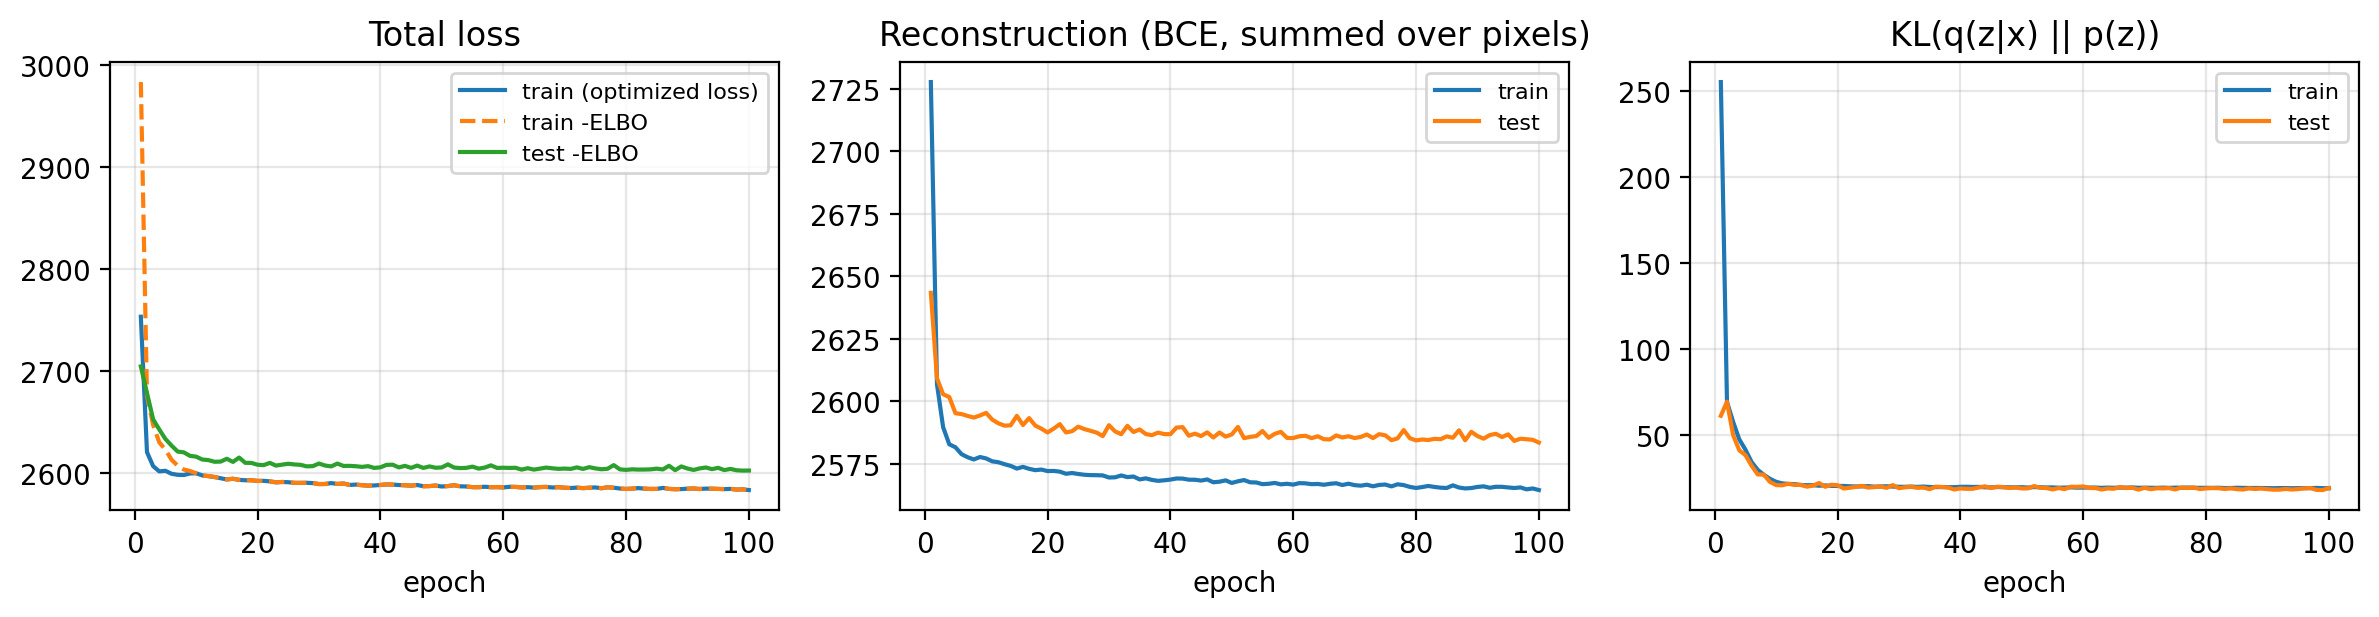

generated_samples.png


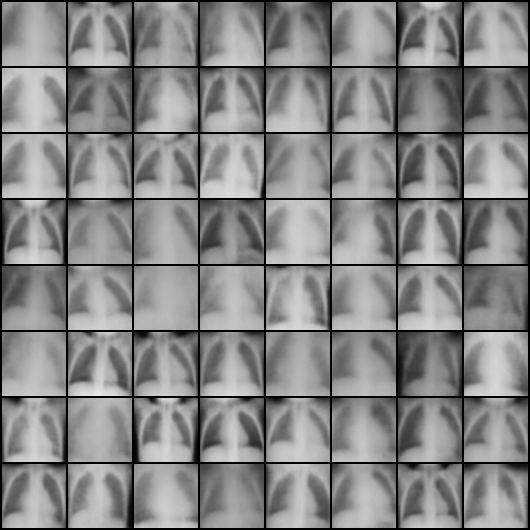

reconstructions.png


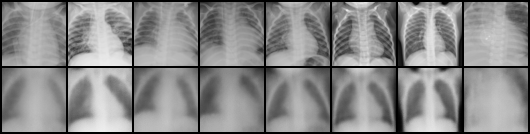

real_examples.png


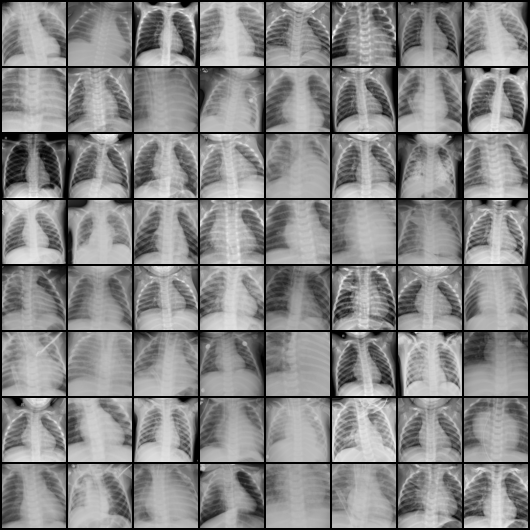

In [27]:
from IPython.display import Image as IPImage, display
for name in ['loss_curves.png', 'generated_samples.png', 'reconstructions.png', 'real_examples.png']:
    print(name); display(IPImage(os.path.join(cfg['out_dir'], name)))